![Banner](../../../../Images/Banner/07_remote_sensing/09_01_banner_rs_banner.png)


# Data Discovery and Access

Petabytes of free imagery sit in public archives.


## Overview

The hard part is no longer getting data but finding the right scenes and loading only the pixels you need. This module covers the modern, cloud-native way to do that: **STAC** catalogs, **Cloud-Optimized GeoTIFFs** read over HTTP, and **lazy data cubes** with Dask, plus the main providers (Microsoft Planetary Computer, AWS Earth Search, NASA Earthdata, Copernicus Data Space, ASF and Google Earth Engine), all through `geolattice.rsense.access`.


## Core concepts

### Learning objectives

1. Describe the STAC model (catalog, collection, item, asset) and how searches work.
2. Define areas of interest (AOIs) from files, GeoDataFrames, geometries or bounding boxes.
3. Build and search your own STAC catalog, then load and mosaic its assets.
4. Search public catalogs for Sentinel-2, Landsat, MODIS and Sentinel-1, and read only the
   pixels you need from Cloud-Optimized GeoTIFFs.
5. Know how to authenticate to NASA Earthdata, CDSE, ASF and Earth Engine.
6. Build, resample and store data cubes with `RasterCube` and Zarr.

> **About the live sections.** the sections from *Searching public STAC catalogs and reading COGs over HTTP (live)* to *NASA Earthdata, Copernicus, ASF and Earth Engine (live, needs accounts)* query internet services. The notebook checks
> whether it can reach them and whether the optional packages are installed: when they are
> available the cells run in full; otherwise they print a short message, and every other
> section still runs on local data from the GeoLattice `data/` folder.

### Data

Dataset are available for download in [GeoLattice Data Folder](https://www.dropbox.com/scl/fo/58n9t8sewax7pffrroxd3/AIWTrjKzklRedtYx0mczwcc?rlkey=0fat0am1b0aai5pieqyx0633j&dl=0)


| Source | Used for |
|---|---|
| `/LC08_20150706_subset/multi_band.tif` and its `MTL.txt` | Landsat 8 bands 2-5 over Onondaga County, New York, 2015-07-16 (notebook 09_01_02): local STAC catalog, lazy loading, simulated cube |
| `/LC08_20150706_subset/DEM_TILES/` | Elevation for the simulated cube |
| `/vector_data/USA/NY_County_GCS.shp` | County boundary as an AOI |
| Microsoft Planetary Computer (live) | Sentinel-2, Landsat, MODIS and Sentinel-1 searches over Syracuse |

### Contents

1. Setup and connectivity check
2. The data-access landscape
3. Areas of interest
4. STAC hands-on: build, search and load your own catalog
5. Searching public STAC catalogs and reading COGs over HTTP (live)
6. One-call loaders for Sentinel-2, Landsat, MODIS, HLS and Sentinel-1 (live)
7. NASA Earthdata, Copernicus, ASF and Earth Engine (live, needs accounts)
8. Lazy loading with Dask
9. Data cubes with `RasterCube` and Zarr
10. Summary and exercises


## Setup and connectivity check

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [ ]:
# Setup for data discovery and access.
#
# 1. Import the pieces a catalogue search needs: JSON, the clock, HTTP, dates,
#    and Shapely geometries (box, Point, shape).
# 2. Import the usual array and vector stack, plus geolattice.rsense.
# 3. Create outputs/ for the local STAC catalog and the simulated cube.
# 4. Print versions and the active compute backend.

%matplotlib inline
import warnings  # warning control
warnings.filterwarnings("ignore", category=UserWarning)  # hide routine library warnings

import importlib.util          # test whether an optional package is installed
import json  # read STAC JSON
import os  # environment variables (credentials)
import time  # timing
import urllib.request  # check whether a server can be reached
from datetime import datetime, timezone  # dates with time zones
from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import xarray as xr  # labelled rasters
import geopandas as gpd  # vector data
import matplotlib.pyplot as plt  # figures
from shapely.geometry import box, Point, shape  # geometry helpers

import geolattice  # GeoLattice
import geolattice.rsense as rs  # GeoLattice remote sensing subpackage

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)  # folder for the files written in this notebook
# versions and backend
print("geolattice", geolattice.__version__, "| geolattice.rsense", rs.__version__, "| backend:", rs.get_backend())

geolattice 0.3.9 | geolattice.rsense 0.2.0.dev0 | backend: cpu


In [ ]:
# Point at the local files the offline sections use, and confirm they exist.
#
# Live catalogue calls can be skipped when the network is down. The Landsat
# scene, its MTL file, the four DEM tiles and the county shapefile are what
# the local STAC catalog and the Dask example are built from.

DATA = Path("../../../../Data")
L8_DIR = DATA / "00_shared" / "data_remote_sensing" / "LC08_20150706_subset"  # the Landsat 8 subset folder
L8_FILE = L8_DIR / "multi_band.tif"  # multi-band Landsat GeoTIFF
L8_MTL = L8_DIR / "LC08_L1TP_015030_20150716_20170226_01_T1_MTL.txt"  # its metadata (MTL) file
DEM_TILES = sorted((L8_DIR / "DEM_TILES").glob("Onondaga_DEM*.TIF"))  # DEM tiles of Onondaga County
COUNTIES = DATA / "00_shared" / "vector_data" / "USA" / "NY_County_GCS.shp"  # New York county boundaries
# check that every local input exists
print("local files present:", all(p.exists() for p in [L8_FILE, L8_MTL, COUNTIES, *DEM_TILES]))

local files present: True


In [ ]:
# Decide what this machine can do before any live search.
#
# 1. reachable() tries to open a URL and returns False on any failure, so a
#    missing network does not crash the notebook.
# 2. ONLINE is True only when Planetary Computer's STAC API answers.
# 3. HAVE records which optional clients are installed (pystac-client,
#    planetary-computer, odc-stac, earthaccess, asf_search, earthengine).
#    Later cells check these flags and print a skip message instead of failing.

def reachable(url, timeout=8):
    try:
        urllib.request.urlopen(url, timeout=timeout)  # try to open the URL
        return True  # the server answered
    except Exception:
        return False  # no connection

ONLINE = reachable(rs.access.CATALOGS["planetary-computer"])  # can the Planetary Computer STAC API be reached?
HAVE = {m: importlib.util.find_spec(m) is not None  # which optional access packages are installed
        for m in ["pystac_client", "planetary_computer", "odc", "earthaccess", "asf_search", "ee"]}
# odc.stac lives inside the odc namespace package
HAVE["odc.stac"] = HAVE.pop("odc") and importlib.util.find_spec("odc.stac") is not None
print("Planetary Computer reachable:", ONLINE)  # online status
print("Optional packages:", HAVE)  # optional packages
if not ONLINE:  # offline
    # explain what will be skipped
    print("Running offline: live sections will be skipped, local sections run normally.")

Planetary Computer reachable: True
Optional packages: {'pystac_client': True, 'planetary_computer': True, 'earthaccess': False, 'asf_search': False, 'ee': False, 'odc.stac': False}


When this notebook was last run (October 2026), Planetary Computer was reachable and
`pystac-client` and `planetary-computer` were installed. The other optional packages
(odc-stac, earthaccess, asf_search, Earth Engine) were not, so:

* The STAC searches and the direct COG reads in the *Searching public STAC catalogs and reading COGs over HTTP (live)* section ran live.
* The `stac_load` cell and the one-call loaders print how to install the `rsense-access`
  extra instead.
* the *NASA Earthdata, Copernicus, ASF and Earth Engine (live, needs accounts)* section skips because no credentials are configured.

The outputs below reflect that environment.


## The data-access landscape


| Provider | What it offers | Access in `geolattice.rsense` | Account needed? |
|---|---|---|---|
| **Microsoft Planetary Computer** | Sentinel-1 RTC/GRD, Sentinel-2 L2A, Landsat C2 L1/L2, MODIS, NAIP, DEMs | `access.stac_search`, `access.stac_load`, `optical.load_sentinel2`, `optical.load_landsat`, `optical.load_modis`, `sar.load_rtc` | No (URLs signed automatically) |
| **Earth Search (AWS, Element 84)** | Sentinel-2 L2A COGs, Landsat C2 | `stac_search(..., catalog="earth-search")` | No |
| **USGS LandsatLook** | Landsat Collection 2 | `catalog="usgs-landsat"` | Requester-pays for direct S3 |
| **NASA Earthdata (CMR)** | MODIS, VIIRS, HLS, GEDI, ICESat-2, SMAP and more | `access.earthdata_search`, `access.earthdata_download`, `optical.load_hls` | Free Earthdata Login |
| **Copernicus Data Space (CDSE)** | Full Sentinel archive (SAFE products) | `access.cdse_search`, `access.cdse_download` | Free CDSE account (downloads) |
| **Alaska Satellite Facility (ASF)** | Sentinel-1 SLC/GRD/bursts, ALOS, NISAR; HyP3 processing | `access.asf_search`, `access.asf_download`, `insar.hyp3` | Earthdata Login |
| **Google Earth Engine** | Curated multi-petabyte catalog with server-side compute | `access.gee_init`, `access.gee_to_xarray` | Earth Engine project |

The first two speak **STAC**, the open standard that most modern archives now use. The
optional dependencies come with the GeoLattice extras `rsense-access` (STAC, odc-stac,
earthaccess), `rsense-sar` (ASF) and `rsense-gee` (Earth Engine).

**Point and click.** The [PyGIS Explorer app](https://zia207-pygis-explorer-app-ou8ehd.streamlit.app/)
does the same searches interactively: draw an area, choose a source (Earth Search, Planetary
Computer, Copernicus Data Space, NOAA Digital Coast or USGS 3DEP lidar), a collection, dates
and a cloud limit, then download the scenes you select. It is a convenient way to see what
exists before writing code.


In [ ]:
# Show the STAC catalogue endpoints built into geolattice.rsense.
#
# rs.access.CATALOGS maps a short name (planetary-computer, earth-search, ...)
# to the URL stac_search will call. You pass the short name, not the URL.

pd.Series(rs.access.CATALOGS, name="STAC endpoint").to_frame()


,STAC endpoint
planetary-computer,https://planetarycomputer.microsoft.com/api/st...
earth-search,https://earth-search.aws.element84.com/v1
usgs-landsat,https://landsatlook.usgs.gov/stac-server
cdse,https://stac.dataspace.copernicus.eu/v1
nasa-lpcloud,https://cmr.earthdata.nasa.gov/stac/LPCLOUD


## Areas of interest


Every search starts with *where* and *when*. `rs.access.aoi_to_geojson` normalizes any AOI
(a vector file path, GeoDataFrame, Shapely geometry, GeoJSON dict or a
`(west, south, east, north)` bounding box) into WGS 84 GeoJSON for the catalog APIs. Our study
area is the city of Syracuse and Onondaga Lake, inside Onondaga County, New York.


In [ ]:
# Turn many kinds of "where" into one GeoJSON geometry.
#
# A STAC search needs a geometry. aoi_to_geojson accepts all of these and
# returns a GeoJSON geometry dict in longitude/latitude:
#   - a (minx, miny, maxx, maxy) tuple
#   - a GeoDataFrame, including one that is still in UTM
#   - a path to a GeoJSON file
#   - a Shapely geometry (here a point buffered by 0.05 degrees)
#   - a polygon read from the county shapefile
# The print shows the geometry type and the first vertex, so you can see that
# the projected copy was converted back to degrees.

bbox = (-76.30, 42.98, -76.05, 43.15)                                  # Syracuse and Onondaga Lake, lon/lat
# the box as a one-row GeoDataFrame
syracuse = gpd.GeoDataFrame({"name": ["Syracuse"]}, geometry=[box(*bbox)], crs=4326)
syracuse_utm = syracuse.to_crs(32618)                                  # a projected copy
syracuse.to_file(OUT / "syracuse_aoi.geojson", driver="GeoJSON")  # save it as GeoJSON
county = gpd.read_file(COUNTIES).query("COUNTY == 'Onondaga County'")  # Onondaga County from the county file

for label, aoi in [("bbox tuple", bbox), ("GeoDataFrame (UTM)", syracuse_utm),  # several ways to give an AOI
                   ("file path", str(OUT / "syracuse_aoi.geojson")),
                   ("shapely point", Point(-76.15, 43.05).buffer(0.05)), ("county polygon", county)]:
    g = rs.access.aoi_to_geojson(aoi)  # convert each to a GeoJSON geometry in lon/lat
    # type and first vertex of the result
    print(f"{label:20s} → {g['type']:12s} first vertex {np.round(np.asarray(g['coordinates'][0][0]).ravel()[:2], 4).tolist()}")

bbox tuple           → Polygon      first vertex [-76.05, 42.98]
GeoDataFrame (UTM)   → Polygon      first vertex [-76.05, 42.98]
file path            → Polygon      first vertex [-76.05, 42.98]
shapely point        → Polygon      first vertex [-76.1, 43.05]
county polygon       → Polygon      first vertex [-75.9902, 43.1855]


Dates are given as a `(start, end)` tuple or a STAC interval string such as
`"2025-06-01/2025-08-31"`. Keep AOIs as files (GeoJSON or GeoPackage) in your project so
every notebook uses the same study area.


## STAC hands-on: build, search and load your own catalog


**STAC** (SpatioTemporal Asset Catalog) describes geospatial data with four objects:

- **Catalog**: a container of links (like a folder).
- **Collection**: a catalog plus shared metadata such as licence and spatial/temporal extent
  (for example, "Sentinel-2 Level-2A").
- **Item**: one scene or tile with a footprint geometry, a datetime and properties such as cloud cover.
- **Asset**: a file belonging to an item (each band, the QA layer, a thumbnail), with its URL.

A search filters items by collection, footprint and date (plus property queries), then you load
the assets you need. To see every piece working without internet, we turn the local Landsat 8
scene into four NDVI tiles and publish them as a STAC catalog with `rs.scale.export_stac`.


In [ ]:
# Build a small STAC catalog from local Landsat NDVI tiles.
#
# STAC is the JSON description catalogues use: a Collection of Items, each Item
# pointing at a file plus the time and place it covers. This cell makes one.
#
# 1. Calibrate the Landsat DNs to top-of-atmosphere reflectance, as in the
#    raster/vector notebook.
# 2. Split the scene into a 2 × 2 grid of NDVI GeoTIFFs.
# 3. export_stac writes a Catalog and a Collection. Every tile gets the same
#    acquisition time and the scene's cloud cover, plus platform and product tags.

mtl = rs.optical.parse_mtl(L8_MTL)
dn = rs.read(L8_FILE, band_names=["blue", "green", "red", "nir"])  # Landsat DN with band names
# DN -> top-of-atmosphere reflectance, band by band
landsat = xr.concat([rs.optical.toa_reflectance(dn.sel(band=n), mtl[f"REFLECTANCE_MULT_BAND_{b}"],
                                                mtl[f"REFLECTANCE_ADD_BAND_{b}"], mtl["SUN_ELEVATION"])
                     for n, b in {"blue": 2, "green": 3, "red": 4, "nir": 5}.items()], dim="band")
landsat = landsat.rio.write_crs(dn.rio.crs)  # attach the CRS
# acquisition time (UTC) from the metadata
acquired = datetime.fromisoformat(f"{mtl['DATE_ACQUIRED']}T{mtl['SCENE_CENTER_TIME'][:8]}").replace(tzinfo=timezone.utc)

H, W = landsat.shape[1:]  # image size
tile_dir = OUT / "tiles"; tile_dir.mkdir(exist_ok=True)  # folder for the tiles
files = []  # paths of the tiles
for i, (r0, r1) in enumerate([(0, H // 2), (H // 2, H)]):  # two row halves ...
    for j, (c0, c1) in enumerate([(0, W // 2), (W // 2, W)]):  # ... and two column halves
        # NDVI of this quarter
        ndvi_tile = rs.optical.index(landsat.isel(y=slice(r0, r1), x=slice(c0, c1)).to_dataset(dim="band"), "NDVI")
        p = tile_dir / f"ndvi_lc08_20150716_r{i}c{j}.tif"  # its file name
        rs.write(ndvi_tile, p)  # save it
        files.append(p)  # remember the path
# write a STAC catalogue describing the four tiles
cat_path = rs.scale.export_stac(files, OUT / "stac", collection_id="onondaga-ndvi",
                                description="NDVI tiles from Landsat 8 OLI, 16 July 2015, Onondaga County NY",
                                datetimes=[acquired] * len(files),
                                properties={"platform": "landsat-8", "product": "NDVI",
                                            "eo:cloud_cover": mtl["CLOUD_COVER"]})
print("Catalog written to", cat_path, "| acquired", acquired)  # where the catalogue is

Catalog written to outputs/stac/catalog.json | acquired 2015-07-16 15:44:48+00:00


In [ ]:
# Open the catalog just written and list its items.
#
# pystac reads the JSON. A Catalog contains Collections; a Collection contains
# Items. Each Item has an id, a datetime, a bounding box, a CRS and one or
# more assets (the actual files). This is the same structure a remote STAC API
# returns for a search hit.

import pystac

catalog = pystac.Catalog.from_file(str(cat_path))  # open the catalogue
collection = next(catalog.get_children())  # its first collection
items = list(collection.get_items())  # the items of the collection
# collection ID, item count and extent
print(f"Collection '{collection.id}': {len(items)} items, extent {np.round(collection.extent.spatial.bboxes[0], 3).tolist()}")
pd.DataFrame([{"id": it.id, "datetime": it.datetime, "bbox": np.round(it.bbox, 3).tolist(),  # one row per item
               "epsg": it.properties.get("proj:epsg") or it.properties.get("proj:code"),
               "asset": list(it.assets)[0]} for it in items])

Collection 'onondaga-ndvi': 4 items, extent [-76.504, 42.768, -75.894, 43.275]


,id,datetime,bbox,epsg,asset
0,ndvi_lc08_20150716_r0c0,2015-07-16 15:44:48+00:00,"[-76.504, 43.019, -76.198, 43.272]",EPSG:32618,data
1,ndvi_lc08_20150716_r0c1,2015-07-16 15:44:48+00:00,"[-76.203, 43.022, -75.898, 43.275]",EPSG:32618,data
2,ndvi_lc08_20150716_r1c0,2015-07-16 15:44:48+00:00,"[-76.498, 42.768, -76.193, 43.022]",EPSG:32618,data
3,ndvi_lc08_20150716_r1c1,2015-07-16 15:44:48+00:00,"[-76.198, 42.772, -75.894, 43.025]",EPSG:32618,data


An item is just JSON. This is what a STAC API returns for each search hit, whether the
catalog is on your disk or in the cloud:


In [ ]:
# Print the raw JSON of the first Item, trimmed so it fits on screen.
#
# This is what travels over the network: properties (datetime, cloud cover, CRS),
# a GeoJSON geometry, and asset hrefs. Clients search on the properties and then
# open the href. The first 1,100 characters are enough to see that shape.

print(json.dumps(items[0].to_dict(), indent=1)[:1100], "...")


{
 "type": "Feature",
 "stac_version": "1.1.0",
 "stac_extensions": [
  "https://stac-extensions.github.io/projection/v2.0.0/schema.json"
 ],
 "id": "ndvi_lc08_20150716_r0c0",
 "geometry": {
  "type": "Polygon",
  "coordinates": [
   [
    [
     -76.19815676744629,
     43.0187417031422
    ],
    [
     -76.19815676744629,
     43.272375840438045
    ],
    [
     -76.50426275675466,
     43.272375840438045
    ],
    [
     -76.50426275675466,
     43.0187417031422
    ],
    [
     -76.19815676744629,
     43.0187417031422
    ]
   ]
  ]
 },
 "bbox": [
  -76.50426275675466,
  43.0187417031422,
  -76.19815676744629,
  43.272375840438045
 ],
 "properties": {
  "platform": "landsat-8",
  "product": "NDVI",
  "eo:cloud_cover": 0.08,
  "proj:code": "EPSG:32618",
  "proj:shape": [
   926,
   815
  ],
  "proj:transform": [
   30.0,
   0.0,
   377925.0,
   0.0,
   -30.0,
   4791765.0
  ],
  "datetime": "2015-07-16T15:44:48Z"
 },
 "links": [
  {
   "rel": "root",
   "href": "../../catalog.j

**Searching** means keeping the items whose footprint intersects the AOI and whose datetime
falls in the window. Public APIs do this server-side; for a static catalog we filter in Python.
Then we **load** the matching assets and mosaic them.


Items intersecting the Syracuse AOI: ['ndvi_lc08_20150716_r0c0', 'ndvi_lc08_20150716_r0c1', 'ndvi_lc08_20150716_r1c0', 'ndvi_lc08_20150716_r1c1']
Items in the wrong month: 0


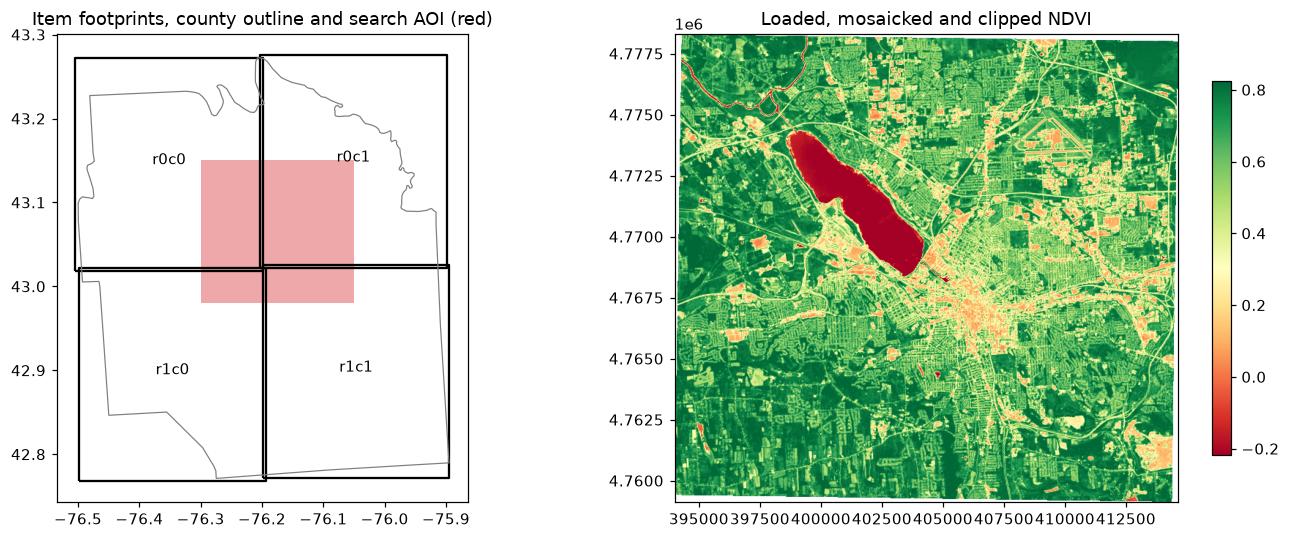

In [ ]:
# Search the local catalog the same way a STAC API search works, then load the hits.
#
# search_static keeps an item only when two things are true:
#   - its footprint intersects the AOI
#   - its datetime falls inside the requested window
# July 2015 should hit the tiles that touch Syracuse. August 2015 should hit none,
# because every tile is dated 16 July.
#
# The hits are then read, mosaicked (they are adjacent quarters of one scene)
# and clipped to the AOI. The left map is the search picture: footprints, the
# county, and the red AOI. The right map is the NDVI that search returned.

def search_static(items, aoi, start, end):
    geom = shape(rs.access.aoi_to_geojson(aoi))  # the AOI as a shapely geometry
    t0, t1 = pd.Timestamp(start, tz="UTC"), pd.Timestamp(end, tz="UTC")  # start and end as UTC timestamps
    # items that overlap the AOI and fall in the date range
    return [it for it in items if shape(it.geometry).intersects(geom) and t0 <= pd.Timestamp(it.datetime) <= t1]

hits = search_static(items, bbox, "2015-07-01", "2015-07-31")  # search July 2015
print("Items intersecting the Syracuse AOI:", [h.id for h in hits])  # the matches
# August 2015 has none
print("Items in the wrong month:", len(search_static(items, bbox, "2015-08-01", "2015-08-31")))

# read the matching tiles
arrays = [rs.read(Path(h.assets["data"].get_absolute_href())).squeeze("band", drop=True) for h in hits]
ndvi_mosaic = rs.mosaic(arrays, "first").squeeze()  # mosaic them
ndvi_aoi = rs.clip(ndvi_mosaic, syracuse)  # clip to the AOI
fig, axes = plt.subplots(1, 2, figsize=(13, 5))  # two panels
footprints = gpd.GeoDataFrame({"id": [it.id[-4:] for it in items]},  # item footprints as polygons
                              geometry=[shape(it.geometry) for it in items], crs=4326)
footprints.boundary.plot(ax=axes[0], color="k")  # their outlines
county.boundary.plot(ax=axes[0], color="grey", lw=0.8)  # county outline
for _, r in footprints.iterrows():  # each footprint
    # label it with the end of its ID
    axes[0].annotate(r.id, (r.geometry.centroid.x, r.geometry.centroid.y), ha="center")
syracuse.plot(ax=axes[0], color="tab:red", alpha=0.4)  # the AOI in red
axes[0].set_title("Item footprints, county outline and search AOI (red)")  # title
# the clipped NDVI
rs.viz.plot_raster(ndvi_aoi, ax=axes[1], cmap="RdYlGn", title="Loaded, mosaicked and clipped NDVI")
plt.tight_layout(); plt.show()  # arrange and draw

The Syracuse AOI lies exactly where the four tiles meet (the corner at about −76.20°,
43.02°), so all four items intersect it and are mosaicked. A search window in August returns
nothing, because every item is dated 16 July 2015. The clipped mosaic has no seams: Onondaga
Lake is strongly negative, downtown Syracuse and the highways are low, and the parks, wooded
ravines and farmland around the city are green.


## Searching public STAC catalogs and reading COGs over HTTP (live)


`rs.access.stac_search` queries a STAC API. For Planetary Computer, asset URLs are signed
automatically, so they can be read without an account. Below we look for Sentinel-2 L2A scenes
over Syracuse in summer 2025 with less than 20 % cloud cover.


In [ ]:
# Live search: Sentinel-2 Level-2A over Syracuse, summer 2025, cloud cover under 20%.
#
# stac_search sends the AOI, the date window and the cloud limit to the catalogue
# and returns STAC Items. Nothing is downloaded yet: only the metadata.
# The table keeps a shortened id, the date, cloud percent and the MGRS tile
# (Sentinel-2's 100 km grid square). If the network or pystac-client is missing,
# the cell prints a skip message and leaves s2_items empty for the cells below.

if ONLINE and HAVE["pystac_client"]:
    t0 = time.perf_counter()  # start the timer
    # Sentinel-2 L2A scenes over the AOI, June-August 2025, up to 20 % cloud
    s2_items = rs.access.stac_search("sentinel-2-l2a", aoi=bbox, dates=("2025-06-01", "2025-08-31"), max_cloud=20)
    # one row per scene: ID, date, cloud cover and tile
    table = pd.DataFrame([{"id": it.id[:44] + "…", "date": it.datetime.date(), "cloud %": round(it.properties["eo:cloud_cover"], 1),
                           "MGRS tile": it.properties.get("s2:mgrs_tile")} for it in s2_items]).sort_values("date")
    # number of scenes, run time and tiles
    print(f"{len(s2_items)} scenes found in {time.perf_counter() - t0:.1f} s; tiles: {sorted(table['MGRS tile'].unique())}")
    display(table)  # show the table
else:
    s2_items = []  # nothing found
    # offline or missing package
    print("Offline or pystac-client missing: skipped. Online this lists matching Sentinel-2 scenes "
          "with dates, cloud cover and MGRS tile.")

23 scenes found in 3.0 s; tiles: ['18TUN', '18TVN']


,id,date,cloud %,MGRS tile
22,S2C_MSIL2A_20250603T155001_R054_T18TUN_20250…,2025-06-03,7.5,18TUN
20,S2A_MSIL2A_20250705T155711_R054_T18TVN_20250…,2025-07-05,18.2,18TVN
21,S2A_MSIL2A_20250705T155711_R054_T18TUN_20250…,2025-07-05,18.5,18TUN
19,S2C_MSIL2A_20250706T155921_R097_T18TUN_20250…,2025-07-06,10.9,18TUN
18,S2C_MSIL2A_20250723T155001_R054_T18TUN_20250…,2025-07-23,0.9,18TUN
17,S2C_MSIL2A_20250723T155001_R054_T18TVN_20250…,2025-07-23,14.0,18TVN
16,S2B_MSIL2A_20250728T154809_R054_T18TUN_20250…,2025-07-28,16.3,18TUN
15,S2A_MSIL2A_20250728T160711_R097_T18TUN_20250…,2025-07-28,11.1,18TUN
14,S2A_MSIL2A_20250728T160711_R097_T18TVN_20250…,2025-07-28,18.6,18TVN
13,S2C_MSIL2A_20250802T154951_R054_T18TUN_20250…,2025-08-02,0.5,18TUN


The search returned 23 Sentinel-2 L2A items on 12 dates in about 3 seconds. Two MGRS tiles
(18TUN and 18TVN) cover the AOI, and two relative orbits (R054 and R097) image it, so most
dates have two items. The cloud percentage is for the whole 110 × 110 km tile, not the AOI. A
"20 % cloud" scene can be clear over Syracuse or not, which is why per-pixel masks (`SCL`)
still matter. The clearest date was 2 August 2025, with 0.5% and 0.2% cloud on the two tiles.

Each item lists its **assets**: one COG per band plus the scene classification (SCL), a true-colour
`visual` image and metadata files.


In [ ]:
# From those search results, pick the clearest day and see what a scene contains.
#
# The clearest item is the one with the lowest eo:cloud_cover. Other items from
# the same date are the neighbouring MGRS tiles needed to cover the AOI.
# Listing asset keys shows the band files you can open (B04 is red). The href is
# a URL; the part before "?" is the Cloud Optimized GeoTIFF itself.

if s2_items:
    # the date of the least cloudy scene
    clear_day = min(s2_items, key=lambda it: it.properties["eo:cloud_cover"]).datetime.date()
    same_day = [it for it in s2_items if it.datetime.date() == clear_day]  # all scenes of that date
    # the date and its tiles
    print(f"Clearest date: {clear_day}; scenes that day: {[it.properties['s2:mgrs_tile'] for it in same_day]}")
    a = same_day[0].assets["B04"]  # the red band asset of the first scene
    print("Assets:", ", ".join(same_day[0].assets))  # all asset names
    # title, media type and URL of the red band
    print("B04:", a.title, "|", a.media_type, "|", a.href.split("?")[0][:110], "…")
else:
    same_day = []  # nothing to use
    print("Skipped (no search results).")  # explain

Clearest date: 2025-08-02; scenes that day: ['18TVN', '18TUN']
Assets: AOT, B01, B02, B03, B04, B05, B06, B07, B08, B09, B11, B12, B8A, SCL, WVP, visual, safe-manifest, granule-metadata, inspire-metadata, product-metadata, datastrip-metadata, tilejson, rendered_preview
B04: Band 4 - Red - 10m | image/tiff; application=geotiff; profile=cloud-optimized | https://sentinel2l2a01.blob.core.windows.net/sentinel2-l2/18/T/VN/2025/08/02/S2C_MSIL2A_20250802T154951_N0511_ …


Because each asset is a **Cloud-Optimized GeoTIFF**, `rs.read` can open it straight from its URL
with Dask chunks. Clipping to the AOI before computing means GDAL fetches only the internal
tiles that overlap Syracuse, a few megabytes instead of the 10,980 × 10,980-pixel band. The AOI
crosses two MGRS tiles, so we read both scenes from the clearest day and mosaic them.

Sentinel-2 L2A products processed since 25 January 2022 (processing baseline 04.00) store
reflectance as `DN + 1000` scaled by 10,000. `rs.optical.scale` removes that offset; forgetting
it biases every index.


Read 6 clipped COGs in 38.8 s; AOI grid (1918, 2063) at 10 m, 79 MB in memory
Median NDVI: 0.671 with the offset removed, 0.440 if it is ignored


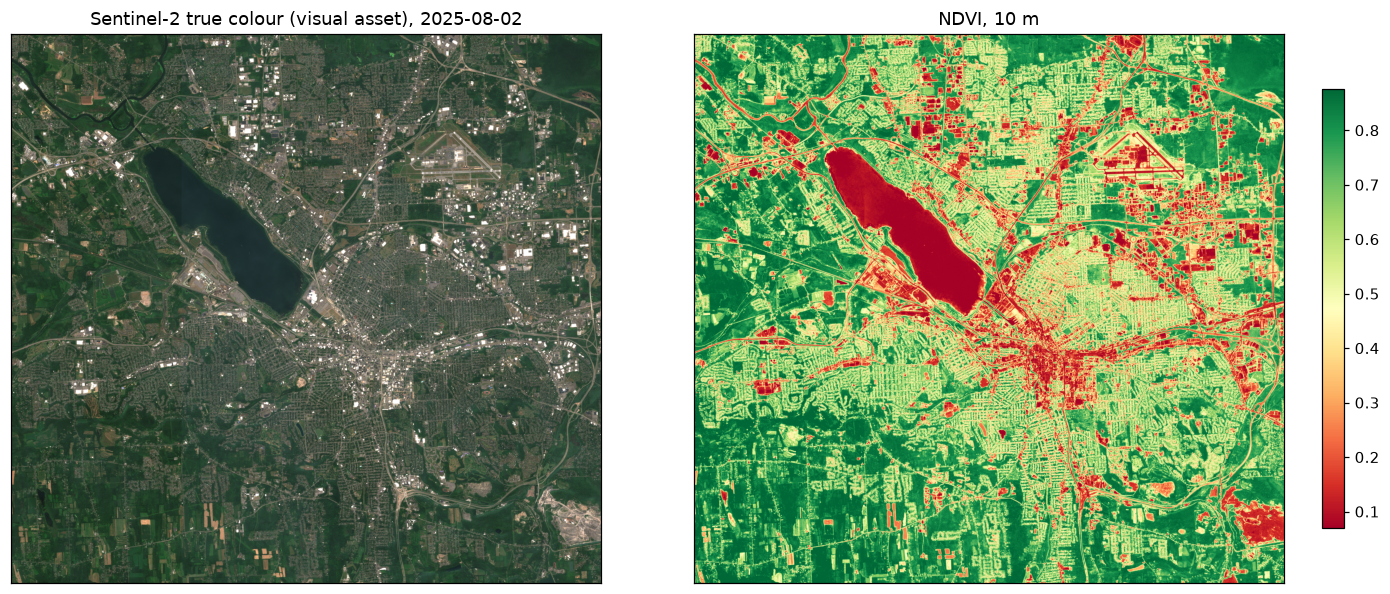

In [ ]:
# Read only the AOI out of the Sentinel-2 COGs, then scale and compute NDVI.
#
# A Cloud Optimized GeoTIFF can be windowed over HTTP. chunks plus clip_box
# ask for the pixels inside the AOI and leave the rest of the tile on the server.
#
# 1. Project the AOI into the scene CRS and, for red (B04), NIR (B08) and the
#    visual overview, read each same-day tile and mosaic the pieces.
# 2. rs.optical.scale converts the integers to surface reflectance and removes
#    the Sentinel-2 baseline offset (boa_offset=-1000). Ignoring that offset
#    shifts NDVI; the two medians show by how much.
# 3. Draw the true-colour visual asset (scaled from 0-255) beside the NDVI.

if same_day:
    t0 = time.perf_counter()  # start the timer
    # EPSG code of the scenes
    crs = same_day[0].properties.get("proj:epsg") or same_day[0].properties.get("proj:code")
    aoi_native = syracuse.to_crs(crs).total_bounds  # AOI bounds in the scenes' CRS
    layers = {}  # one mosaic per band
    for band in ["B04", "B08", "visual"]:  # red, NIR and the true-colour image
        # read each scene lazily and keep only the AOI
        parts = [rs.read(it.assets[band].href, chunks={"x": 1024, "y": 1024}).rio.clip_box(*aoi_native) for it in same_day]
        layers[band] = rs.mosaic([p.compute() for p in parts], "first")  # load and mosaic
    # number of files read and run time
    print(f"Read {3 * len(same_day)} clipped COGs in {time.perf_counter() - t0:.1f} s; "
          f"AOI grid {layers['B04'].shape[-2:]} at 10 m, {sum(v.nbytes for v in layers.values()) / 1e6:.0f} MB in memory")
    # red and NIR as a Dataset
    s2 = xr.Dataset({"B04": layers["B04"].squeeze(), "B08": layers["B08"].squeeze()})
    s2 = s2.assign_coords(time=pd.Timestamp(clear_day))  # add the date
    # DN -> reflectance, removing the 1,000 offset of newer products
    s2_sr = rs.optical.scale(s2, sensor="sentinel2", boa_offset=-1000)
    s2_ndvi = rs.optical.index(s2_sr, "NDVI", sensor="sentinel2")  # NDVI with the offset handled
    # NDVI without removing the offset (wrong)
    naive = rs.optical.index(s2 / 10_000, "NDVI", sensor="sentinel2")
    # the difference the offset makes
    print(f"Median NDVI: {float(s2_ndvi.median()):.3f} with the offset removed, "
          f"{float(naive.median()):.3f} if it is ignored")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))  # two panels
    vis = layers["visual"].transpose("y", "x", "band").values  # true-colour image as (y, x, band)
    xmin, ymin, xmax, ymax = layers["visual"].rio.bounds()  # its extent
    axes[0].imshow(np.nan_to_num(vis / 255.0), extent=[xmin, xmax, ymin, ymax])  # show it
    axes[0].set_title(f"Sentinel-2 true colour (visual asset), {clear_day}")  # title
    rs.viz.plot_raster(s2_ndvi.rio.write_crs(crs), ax=axes[1], cmap="RdYlGn", title="NDVI, 10 m")  # NDVI map
    for a in axes: a.set_xticks([]); a.set_yticks([])  # no ticks
    plt.tight_layout(); plt.show()  # arrange and draw
else:
    # offline
    print("Skipped (offline). Online this reads only the AOI from the Sentinel-2 COGs and maps NDVI.")

Reading the red, NIR and true-colour assets from both tiles, clipped to the AOI, took 25-40 seconds
on this connection (it varies from run to run). It produced a 1,918 × 2,063 grid at 10 m (79 MB in memory),
although each full band is 10,980 × 10,980 pixels. Only the internal COG tiles overlapping
Syracuse were fetched.

The 10 m image resolves individual streets, the runways of Syracuse Hancock International
Airport and the lakeshore far better than the 30 m Landsat scene of the *STAC hands-on: build, search and load your own catalog* section.

**The offset matters.** With the +1000 offset removed, the median NDVI is 0.671. Ignoring it
gives 0.440, a 34% underestimate that would look like a real vegetation change.

For whole time series, `rs.access.stac_load` turns the search results into a **lazy** xarray
Dataset (one variable per band, dimensions time × y × x) using **odc-stac**, which handles
reprojection to a common grid and grouping by day.


In [ ]:
# Build a lazy time × y × x cube from the search hits.
#
# stac_load (via odc-stac) stacks every item onto one grid at 20 m, keeping
# red, NIR and the scene-classification layer. chunks makes the result a Dask
# array: the print shows the shape, but no pixel has been downloaded until
# something calls .compute(). Without odc-stac, or without search results, the
# cell explains what was skipped.

if s2_items and HAVE["odc.stac"]:
    # a lazy cube of all scenes on a 20 m grid
    cube_s2 = rs.access.stac_load(s2_items, bands=["B04", "B08", "SCL"], aoi=bbox, resolution=20,
                                  chunks={"x": 1024, "y": 1024})
    print(cube_s2)  # show its structure
    # nothing has been downloaded yet
    print(f"Lazy size: {cube_s2.nbytes / 1e6:.0f} MB across {cube_s2.sizes['time']} dates: nothing downloaded yet")
elif s2_items:  # odc-stac missing
    # how to install it
    print("odc-stac is not installed: install it with  pip install 'geolattice[rsense-access]'  to build lazy "
          "time × y × x cubes from search results.")
else:
    print("Skipped (offline).")  # offline

odc-stac is not installed: install it with  pip install 'geolattice[rsense-access]'  to build lazy time × y × x cubes from search results.


## One-call loaders (live)


For the common sensors `geolattice.rsense` wraps search → load → scale to reflectance → cloud mask →
canonical band names in a single call. Each returns a lazy Dataset ready for indices and
composites. The loaders use odc-stac, so they need the `rsense-access` extra.

| Loader | Collection | Masking |
|---|---|---|
| `rs.optical.load_sentinel2` | Sentinel-2 L2A (Planetary Computer or Earth Search) | SCL classes |
| `rs.optical.load_landsat` | Landsat Collection 2 Level-2 (choose `platforms`) | QA_PIXEL bits |
| `rs.optical.load_modis` | MOD09A1 8-day surface reflectance | state flags |
| `rs.optical.load_hls` | HLS L30/S30 v2.0 from NASA (Earthdata login) | Fmask bits |
| `rs.sar.load_rtc` | Sentinel-1 radiometrically terrain-corrected γ⁰ | n/a |

Even without odc-stac, the same searches show what each sensor offers for the AOI:


In [ ]:
# Ask the same question of four sensors: how many scenes cover this AOI and season?
#
# One AOI (Syracuse), one window (June-August 2025), four collections.
# Sentinel-2 and Landsat are filtered to cloud cover under 20%. MODIS 8-day
# composites and Sentinel-1 radar have no optical cloud field, so that filter
# is omitted. MODIS items store a start/end interval rather than a single
# datetime, so the date falls back to start_datetime.

if ONLINE and HAVE["pystac_client"]:
    rows = []  # one row per sensor
    # several collections to search
    for name, col, kw in [("Sentinel-2 L2A", "sentinel-2-l2a", {"max_cloud": 20}),
                          ("Landsat 8/9 C2 L2", "landsat-c2-l2", {"max_cloud": 20}),
                          ("MODIS MOD09A1 (8-day)", "modis-09A1-061", {}),
                          ("Sentinel-1 RTC", "sentinel-1-rtc", {})]:
        # search this collection
        found = rs.access.stac_search(col, aoi=bbox, dates=("2025-06-01", "2025-08-31"), **kw)
        # number of items found
        rows.append({"sensor": name, "collection": col, "items, Jun-Aug 2025": len(found),
                     "distinct dates": len({pd.Timestamp(it.datetime or it.properties["start_datetime"]).date()
                                            for it in found})})   # MODIS items carry a start/end interval
    display(pd.DataFrame(rows).set_index("sensor"))  # show the table
else:
    print("Offline: skipped.")  # offline

,collection,"items, Jun-Aug 2025",distinct dates
sensor,,,
Sentinel-2 L2A,sentinel-2-l2a,23,12
Landsat 8/9 C2 L2,landsat-c2-l2,9,9
MODIS MOD09A1 (8-day),modis-09A1-061,10,5
Sentinel-1 RTC,sentinel-1-rtc,8,8


For June-August 2025 over the same AOI:

| Sensor | Items | Distinct dates | Why |
|---|---|---|---|
| Sentinel-2 | 23 | 12 | Two tiles and two orbits |
| Landsat 8/9 | 9 | 9 | Below 20% cloud; one path/row per date |
| Sentinel-1 RTC | 8 | 8 | Radar ignores clouds, so no cloud filter applies |
| MODIS MOD09A1 | 10 | 5 | Terra and Aqua pairs; see below |

The MODIS row shows why you should **check a catalogue's completeness**. The 10 items are
five 8-day composite periods, each from both Terra (`MOD09A1`) and Aqua (`MYD09A1`), and
they all start between 25 May and 26 June. When this notebook was run, Planetary Computer's
`modis-09A1-061` collection had no composites for this tile between 26 June and 25 November
2025. The search was correct; the archive had a gap. Before concluding that "nothing
happened" in a period, confirm that the data exist.


In [ ]:
# One-call loaders: search, scale, mask and stack in a single function.
#
# load_sentinel2 returns a time series of reflectance bands at 20 m.
# composite("median") collapses that series into one cloud-resistant image.
# MNDWI on the composite highlights water.
#
# The same pattern then opens a Landsat series, a MODIS series and a
# Sentinel-1 RTC series. Only the shapes are printed. odc-stac has to be
# installed; otherwise the cell says how to add it.

if ONLINE and HAVE["odc.stac"]:
    t0 = time.perf_counter()  # start the timer
    # load Sentinel-2 surface reflectance for the summer
    s2 = rs.optical.load_sentinel2(bbox, ("2025-06-01", "2025-08-31"), max_cloud=30,
                                   bands=["blue", "green", "red", "nir", "swir16"], resolution=20)
    comp = s2.rs.composite("median").compute()  # median composite
    # number of scenes and run time
    print(f"Loaded and composited {s2.sizes['time']} scenes in {time.perf_counter() - t0:.0f} s")
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))  # two panels
    rs.viz.plot_rgb(comp, "true_color", ax=axes[0], title="Sentinel-2 summer median, Syracuse")  # true colour
    # MNDWI water index
    rs.viz.plot_raster(comp.rs.index("MNDWI"), ax=axes[1], cmap="Blues", title="MNDWI (water)")
    plt.tight_layout(); plt.show()  # arrange and draw

    # Landsat red and NIR, 2024-2025, at 60 m
    landsat_ts = rs.optical.load_landsat(bbox, ("2024-01-01", "2025-12-31"), bands=["red", "nir"], resolution=60)
    # MODIS red and NIR, 2025
    modis_ts = rs.optical.load_modis(bbox, ("2025-01-01", "2025-12-31"), bands=["red", "nir"])
    # Sentinel-1 RTC backscatter, July 2025
    s1 = rs.sar.load_rtc(bbox, ("2025-07-01", "2025-07-31"), polarizations=("vv", "vh"), orbit="descending", resolution=40)
    # every loaded dataset
    for name, d in [("Landsat 8/9", landsat_ts), ("MODIS 8-day", modis_ts), ("Sentinel-1 RTC", s1)]:
        # dates, grid size and variables
        print(f"{name:15s} {d.sizes['time']:3d} dates, grid {d.sizes['y']}×{d.sizes['x']}, vars {list(d.data_vars)}")
elif ONLINE:  # online but odc-stac missing
    # how to install it
    print("odc-stac is not installed, so the one-call loaders are skipped. Install the extra with\n"
          "    pip install 'geolattice[rsense-access]'\n"
          "and rerun: this cell then builds a cloud-free Sentinel-2 median and loads Landsat, MODIS and "
          "Sentinel-1 time series for the AOI.")
else:
    print("Offline: skipped.")  # offline

odc-stac is not installed, so the one-call loaders are skipped. Install the extra with
    pip install 'geolattice[rsense-access]'
and rerun: this cell then builds a cloud-free Sentinel-2 median and loads Landsat, MODIS and Sentinel-1 time series for the AOI.


## NASA Earthdata, Copernicus, ASF and Earth Engine (live, needs accounts)


These services need free accounts. Credentials are read from the environment (or `~/.netrc`
for Earthdata), so they never appear in notebooks:

| Service | Set these environment variables | Sign up | GeoLattice extra |
|---|---|---|---|
| NASA Earthdata / ASF | `EARTHDATA_USERNAME`, `EARTHDATA_PASSWORD` | urs.earthdata.nasa.gov | `rsense-access`, `rsense-sar` |
| Copernicus Data Space | `CDSE_USERNAME`, `CDSE_PASSWORD` | dataspace.copernicus.eu | `rsense-access` |
| Google Earth Engine | run `rs.access.gee_init(project="my-project", authenticate=True)` once | earthengine.google.com | `rsense-gee` |

The cell below runs only for the services you have configured.


In [ ]:
# Searches that need a free account. Without credentials, both blocks skip.
#
# EARTHDATA_USERNAME (and the earthaccess package) unlocks NASA Earthdata.
# Here that is a count of GEDI footprint granules, plus a short Sentinel-1 SLC
# search at the Alaska Satellite Facility.
# CDSE_USERNAME unlocks Copernicus Data Space. The search lists Sentinel-1 GRD
# products. The download line stays commented because one SAFE file is about 1 GB.

have_earthdata = ONLINE and bool(os.environ.get("EARTHDATA_USERNAME")) and HAVE["earthaccess"]
have_cdse = ONLINE and bool(os.environ.get("CDSE_USERNAME"))  # CDSE search needs credentials in the environment

if have_earthdata:  # NASA Earthdata available
    # GEDI L2A granules over the AOI
    gedi = rs.access.earthdata_search("GEDI02_A", aoi=bbox, dates=("2022-01-01", "2022-12-31"), count=5)
    print("GEDI L2A granules:", len(gedi))  # how many
    if HAVE["asf_search"]:  # ASF search package installed
        # Sentinel-1 SLC scenes at ASF
        s1_slc = rs.access.asf_search(aoi=bbox, dates=("2025-07-01", "2025-07-31"), product="SLC", max_results=5)
        print("Sentinel-1 SLC scenes at ASF:", len(s1_slc))  # how many
else:
    print("Earthdata/ASF: no credentials, package missing or offline, skipped.")  # skipped

if have_cdse:  # CDSE available
    # Sentinel-1 GRD products at CDSE
    cdse_items = rs.access.cdse_search("sentinel1-grd", aoi=bbox, dates=("2025-07-01", "2025-07-15"))
    print("CDSE Sentinel-1 GRD products:", len(cdse_items))  # how many
    # rs.access.cdse_download(cdse_items[0], OUT / "safe")   # ~1 GB zipped SAFE
else:
    print("CDSE: no credentials or offline, skipped.")  # skipped

Earthdata/ASF: no credentials, package missing or offline, skipped.
CDSE: no credentials or offline, skipped.


Earth Engine runs computations on Google's servers; `gee_to_xarray` pulls the result into
xarray so the rest of `geolattice.rsense` applies unchanged:

```python
rs.access.gee_init(project="my-ee-project")
ds = rs.access.gee_to_xarray("COPERNICUS/S2_SR_HARMONIZED", aoi=bbox, scale=20,
                             bands=["B4", "B8"], dates=("2025-06-01", "2025-08-31"))
ndvi = rs.optical.index(ds, "NDVI", bands={"red": "B4", "nir": "B8"})
```


## Lazy loading with Dask


Whether data come from a catalog or a local file, the pattern is the same: open lazily with
chunks, describe the computation, and compute only the result. Here the local Landsat file
stands in for a remote COG.


In [ ]:
# A lazy Dask pipeline on the local Landsat file.
#
# chunks of 512 × 512 keep the read as a task graph. index() builds NDVI from
# the DNs without loading them: fine for showing the mechanics, not a physical
# NDVI, because the DNs have not been calibrated.
#
# clip to the Syracuse box, then mean().compute(), forces Dask to run. Only the
# chunks that overlap the AOI are read from disk. The task-graph size printed
# first is the plan; the mean is the result.

lazy = rs.read(L8_FILE, band_names=["blue", "green", "red", "nir"], chunks={"x": 512, "y": 512})
ndvi_lazy = rs.optical.index(lazy.to_dataset(dim="band"), "NDVI")              # DN-based, for illustration
# chunk size and number of tasks in the Dask graph
print("Chunks:", ndvi_lazy.data.chunksize, "| tasks in graph:", len(ndvi_lazy.data.__dask_graph__()))
print("Nothing computed yet:", type(ndvi_lazy.data).__name__)  # still a Dask array: nothing computed

t0 = time.perf_counter()  # start the timer
# clip and average, then compute
aoi_mean = float(rs.clip(ndvi_lazy.rio.write_crs(lazy.rio.crs), syracuse).mean().compute())
# result and run time
print(f"Mean (DN-based) NDVI over the Syracuse AOI: {aoi_mean:.3f} (computed in {time.perf_counter() - t0:.2f} s, "
      "reading only the chunks that overlap the AOI)")

Chunks: (512, 512) | tasks in graph: 129
Nothing computed yet: Array
Mean (DN-based) NDVI over the Syracuse AOI: 0.379 (computed in 0.17 s, reading only the chunks that overlap the AOI)


The NDVI here is computed from raw DNs, which is fine for showing the lazy mechanics but not
for analysis: DNs carry an additive offset, so DN-based NDVI differs from the reflectance-based
values of the *STAC hands-on: build, search and load your own catalog* section. Always scale to reflectance first.

## Data cubes with `RasterCube` and Zarr

A **data cube** stacks images of the same grid through time. `RasterCube` is a thin wrapper
around an xarray Dataset (time, y, x) that adds construction from files, period selection,
temporal resampling and Zarr persistence; `cube.ds` is always a plain Dataset.

We only have a single-date Landsat scene, so to practise the mechanics we **simulate** a
two-year monthly NDVI series from the real July NDVI: each pixel greens up in spring and
browns down in autumn, with the peak a little later on the higher southern hills, a smaller
seasonal swing for dense forest, a winter low for everything, and random cloud gaps. The values
are illustrative; the workflow is identical for a real Sentinel-2 or Landsat cube from the *One-call loaders (live)* section.


In [ ]:
# Simulate two years of monthly NDVI and open the files as a RasterCube.
#
# There is no local time series on disk, so this cell builds a plausible one
# from the July Landsat NDVI and the DEM:
#   - coarsen by 4 makes 120 m pixels, small enough to store 24 dates easily
#   - the seasonal peak is mid-July, up to two weeks later on the higher ground
#   - vegetated pixels (high July NDVI) swing the most; water and city swing least
#   - about 15% of pixels are punched out as cloud (NaN) at random
# RasterCube.from_files stacks the GeoTIFFs on a time axis. Displaying cube
# shows that stack without extra plotting.

base = rs.optical.index(landsat.coarsen(x=4, y=4, boundary="trim").mean().to_dataset(dim="band"), "NDVI")
base = base.rio.write_crs(landsat.rio.crs)                                     # 120 m July NDVI
dem = rs.mosaic([rs.read(p).squeeze("band", drop=True) for p in DEM_TILES])  # mosaic of the DEM tiles
elev = dem.astype("float32").rio.reproject_match(base).values  # elevation on the NDVI grid
rng = np.random.default_rng(1)  # random generator
dates = pd.date_range("2024-01-01", periods=24, freq="MS") + pd.Timedelta("14D")  # 24 monthly dates (mid-month)
peak_doy = 197 + (np.clip(elev, 100, 650) - 100) / 550 * 14         # mid-July, up to two weeks later on the hills
amp = np.clip(base.values - 0.25, 0.1, 0.6)                          # vegetated pixels swing most, water and city least
paths = []  # file paths of the monthly images
for t in dates:  # every date
    phase = np.cos(2 * np.pi * (t.dayofyear - peak_doy) / 365.25)    # +1 at the peak, −1 in midwinter
    # seasonal NDVI that varies with elevation, plus noise
    img = base.values - amp * (1 - phase) / 2 + rng.normal(0, 0.02, base.shape)
    clouds = rng.random(base.shape) < 0.15  # random 15 % cloud cover
    p = OUT / "cube" / f"ndvi_{t:%Y%m%d}.tif"; p.parent.mkdir(exist_ok=True)  # file name and folder
    # save the month with clouds as NaN
    rs.write(base.copy(data=np.where(clouds, np.nan, img).astype("float32")).rename("ndvi"), p)
    paths.append(p)  # remember the path
cube = rs.RasterCube.from_files(paths, dates, band_names=["ndvi"])  # build a cube from the files and dates
cube  # show it

<RasterCube 24 dates × 463×407 px, bands=['ndvi'], 2024-01-15 → 2025-12-15, crs=EPSG:32618>

In [ ]:
# Three time-axis operations on the cube.
#
# sel_period keeps June, July and August across both years.
# resample("QS-DEC", "median") builds seasonal medians. "QS-DEC" means quarters
# that start in December, so winter is Dec-Feb rather than Jan-Mar.
# valid_fraction is the share of finite pixels on each date (the rest are the
# cloud holes written above). head() shows the first few dates only.

summer = cube.sel_period("2024-01-01", "2025-12-31", months=[6, 7, 8])
seasonal = cube.resample("QS-DEC", "median")  # seasonal (quarterly) median composites
# number of summer scenes and composites
print("Summer scenes:", len(summer.times), "| seasonal composites:", len(seasonal.times))
cube.valid_fraction().to_series().round(3).head()  # share of valid pixels in the first dates

Summer scenes: 6 | seasonal composites: 9


time
2024-01-15    0.656
2024-02-15    0.656
2024-03-15    0.657
2024-04-15    0.657
2024-05-15    0.657
Name: ndvi, dtype: float64

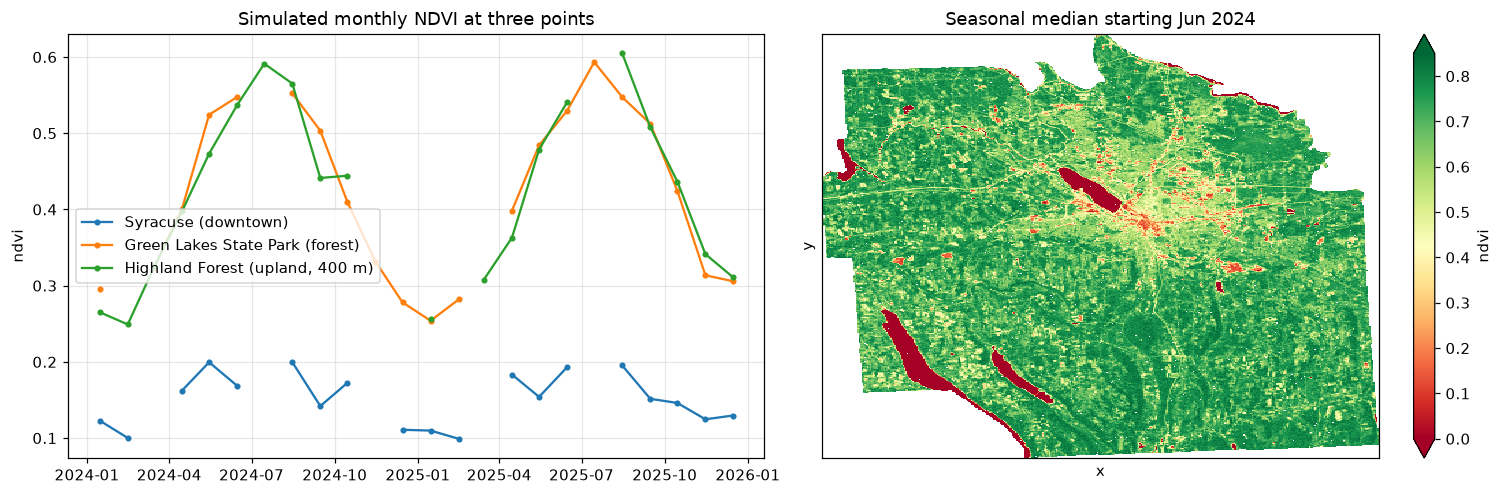

In [ ]:
# Extract a time series at three named points and map one seasonal composite.
#
# The cube is in the Landsat CRS, so longitude/latitude have to be transformed
# before they can index it. plot_timeseries draws one line per point.
# isel(time=2) is one seasonal median (the third quarter in the resampled cube).

from pyproj import Transformer
to_cube = Transformer.from_crs(4326, cube.crs, always_xy=True)  # lon/lat -> cube CRS
# three points in lon/lat
lonlat = {"Syracuse (downtown)": (-76.147, 43.048), "Green Lakes State Park (forest)": (-75.970, 43.058),
          "Highland Forest (upland, 400 m)": (-75.935, 42.855)}
pts = {k: to_cube.transform(*v) for k, v in lonlat.items()}  # the points in the cube CRS
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))  # two panels
# NDVI time series at the points
rs.viz.plot_timeseries(cube["ndvi"], pts, ax=axes[0]); axes[0].set_title("Simulated monthly NDVI at three points")
seasonal["ndvi"].isel(time=2).plot(ax=axes[1], cmap="RdYlGn", vmin=0, vmax=0.85)  # one seasonal composite
# title, no ticks
axes[1].set_title(f"Seasonal median starting {seasonal.times[2]:%b %Y}"); axes[1].set_xticks([]); axes[1].set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

The simulated series behave as designed:

* The forest points (Green Lakes and Highland Forest) cycle between about 0.25 in winter and
  0.6 in July.
* Downtown Syracuse stays between 0.1 and 0.2 all year.
* Gaps are the simulated cloud masks. About 66% of each date is valid: 77% of pixels lie
  inside the county, and 15% of those are clouded.

The June-August 2024 seasonal median map is the July NDVI pattern again: lakes, city and
highways low, everything else green. Real cubes from the *One-call loaders (live)* section work exactly the same way.

Large cubes belong in **Zarr**: chunked, compressed and readable in parallel from disk or cloud
storage. `rs.scale.to_zarr_cube` writes with sensible chunks (512 × 512 pixels, full time) and can
**append** new dates as they arrive, the usual pattern for monitoring systems.


In [ ]:
# Save the cube as Zarr, in two appends, and read it back.
#
# A Zarr store can grow along time. The first call writes year 1 (dates 0-11).
# The second appends year 2 on the time dimension. open_cube reopens the store
# lazily. The last line checks that the values, including the cloud NaNs, match
# the cube still held in memory.

store = OUT / "ndvi_cube.zarr"
rs.scale.to_zarr_cube(cube.ds.isel(time=slice(0, 12)), store)               # first year
rs.scale.to_zarr_cube(cube.ds.isel(time=slice(12, 24)), store, append_dim="time")   # append second year
z = rs.scale.open_cube(store)  # open the saved Zarr cube
# size, chunks and CRS
print("Zarr cube:", dict(z.sizes), "| chunks:", z["ndvi"].data.chunksize, "| CRS:", z.rio.crs)
# same values as the in-memory cube
print("Identical to the in-memory cube:", bool(np.allclose(z["ndvi"].values, cube["ndvi"].values, equal_nan=True)))

Zarr cube: {'time': 24, 'y': 463, 'x': 407} | chunks: (12, 463, 407) | CRS: EPSG:32618
Identical to the in-memory cube: True


## Summary and exercises


**Key ideas**

- STAC organises imagery as catalogs, collections, items and assets; search by collection, AOI,
  date and properties, then load only the assets and pixels you need.
- Cloud-Optimized GeoTIFFs can be read straight from their URLs; clipping before computing
  fetches only the overlapping internal tiles.
- Check product conventions such as the Sentinel-2 `+1000` offset before computing indices.
- The loaders of `geolattice.rsense` combine search, lazy loading, scaling, cloud masking and band
  naming in one call (extra `rsense-access`).
- Keep credentials in environment variables; Planetary Computer and Earth Search need none.
- Work lazily with Dask, store cubes in Zarr, and publish your own products as STAC.

**Exercises**

1. (Online) Repeat the Sentinel-2 search for your own AOI and plot cloud cover against date.
   How many scenes pass a 10 % threshold?
2. (Online) Search the same AOI with `catalog="earth-search"` and compare the item count and
   asset names with Planetary Computer.
3. Filter the local catalog by its `eo:cloud_cover` property in `search_static`.
4. (Online) Read the `SCL` asset for the clearest day and mask clouds and water before
   computing the NDVI median.
5. Resample the simulated cube to annual maxima and map the year-to-year difference.
6. (Online, Earthdata account) Search HLS for your AOI with `rs.optical.load_hls(..., product="both")`
   and count how many more observations you get than with Landsat alone.

**Next:** The companion notebook (`09_01_04`) maps every `get_images` call.
The optical notebooks (07_02) then begin with MODIS, the daily global workhorse.
